# 05 - Clasificación: centroide más cercano y k-NN

**Curso de Aprendizaje Automático**

En el notebook  03 agrupamos datos **sin usar las etiquetas**. Aquí las recuperamos: dado un
objeto nuevo, queremos **predecir su clase**. Es el mismo `argmin` sobre distancias del notebook
02, con una diferencia importante en cómo se evalúa el resultado.



## Preparación

In [2]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_circles, make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import mode

# baile: la libreria del curso
src = os.path.join(os.getcwd(), 'src')
if src not in sys.path:
    sys.path.append(src)
from SimpleClassifying import dibuja_frontera_2D
from SimpleClustering import plotClusters, plotPCA

np.random.seed(0)

## 1. De no supervisado a supervisado

La diferencia con los notebooks 03 es una sola columna:

| | Recibe | Objetivo | ¿Hay respuesta correcta? |
|---|---|---|---|
| Agrupamiento (03) | $X$ | descubrir estructura | no, se evalúa con SSE o silueta |
| **Clasificación** (este) | $X$ **y** $Y$ | predecir $y$ de un objeto nuevo | **sí** |

Que exista una respuesta correcta permite **medir si el
modelo acierta**. Pero introduce un  problema nuevo: un modelo puede
acertar en los datos que ya vio y fallar en los que no.

Los dos algoritmos de este notebook reutilizamos conceptos que ya vimos:

- **Centroide más cercano (NC)**: calcula el centroide de cada clase y asigna cada objeto nuevo al
  centroide más próximo. Es exactamente el método `predict` de la plantilla `Clustering` del
  notebook 03, solo que los centroides no se descubren: se calculan con las etiquetas.
- **k-NN**: busca los $k$ objetos más parecidos en el entrenamiento y vota. Es el
  `vecino_mas_cercano` del notebook 02, sección 7.1, generalizado a $k$ vecinos.

Lo nuevo es el **protocolo de evaluación**.


## 2. Los datos

Usamos iris, ya conocido. Como queremos **dibujar fronteras de decisión**, y eso solo se puede
hacer en el plano, proyectamos las cuatro dimensiones a dos con PCA.


In [3]:
bunch = load_iris()
data, target = bunch['data'], bunch['target']
data2d = PCA(n_components=2).fit_transform(data)

print('original :', data.shape)
print('proyectado:', data2d.shape)
print('clases    :', bunch.target_names)

original : (150, 4)
proyectado: (150, 2)
clases    : ['setosa' 'versicolor' 'virginica']


> **Cuidado con este atajo.** Proyectar a 2D es una decisión **para poder graficar**, no una
> mejora del modelo: PCA descarta información. Cuando trabajes con tus datos, entrena en el espacio completo y usa la
> proyección solo para las figuras.


## 3. Entrenamiento y prueba

Nos interesa clasificar muestras **desconocidas**, pero solo contamos con `data`. La solución es apartar una parte de los datos y fingir que no los hemos visto. Dividimos el conjunto en dos:
1. un conjunto de **entrenamiento**, que el algoritmo utiliza para ajustar sus parámetros. En el caso de nearest centroid, los parámetros son los centroides.
2. un conjunto de test para evaluar la capacidad de generalización del modelo

La función `train_test_split` del paquete `model_selection` hace la divisón. La usaremos para generar una partición 70% / 30% en entrenamiento y prueba.

Dos cosas a tener en cuenta:

- `stratify=target` conserva la proporción de clases en ambas partes. Sin él, una partición desafortunada podría dejar pocas setosa en entrenamiento.
- `random_state=1` fija el sorteo para que el resultado sea reproducible.

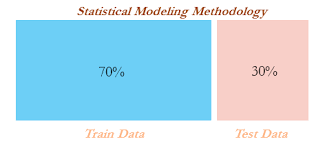

In [4]:
X_train, X_test, y_train, y_test = train_test_split(data2d, target,
                                                    test_size=0.30,
                                                    random_state=1,
                                                    stratify=target)
print('entrenamiento:', X_train.shape, ' prueba:', X_test.shape)
print('clases en entrenamiento:', np.bincount(y_train))
print('clases en prueba       :', np.bincount(y_test))

entrenamiento: (105, 2)  prueba: (45, 2)
clases en entrenamiento: [35 35 35]
clases en prueba       : [15 15 15]


**Regla que no se rompe en todo el curso**: el conjunto de prueba se toca **una sola vez**, al
final, para reportar el resultado. Todo lo demás (elegir $k$, elegir la distancia, escalar) se
decide usando solo el entrenamiento. En la sección 8  de este notebook veremos cómo hacerlo bien.


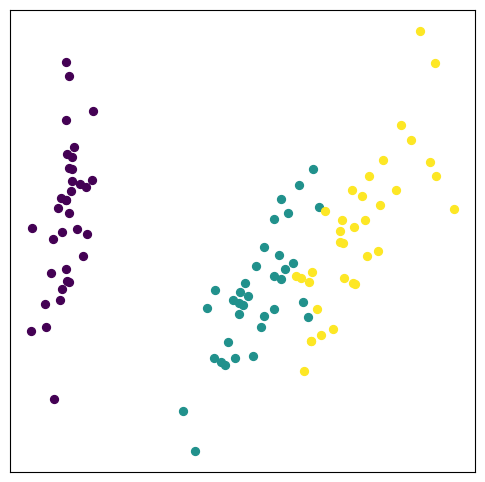

In [4]:
plotClusters(X_train, y_train)
plt.show()

## 4. El centroide más cercano (NC)

El clasificador de **centroide más cercano** es un modelo de clasificación lineal, muy barato de entrenar, que se adapta bien a problemas de alta dimensión. Para cada clase se calcula el centroide de sus datos, es decir, el valor promedio de cada característica en el conjunto de entrenamiento. Para clasificar un objeto nuevo se le asigna la clase de su centroide más cercano.

Es el algoritmo más simple posible que usa las etiquetas: todo el entrenamiento consiste en promediar.

> **Nota.** Existe una variante llamada *nearest shrunken centroids* (conocida como PAM, por *predictive analysis for microarrays*) que además **contrae** cada centroide de clase hacia el centroide general. La idea es que si una característica no aporta información para una clase, su centroide para esa clase estará cerca del general y conviene ignorarla. Esa variante es útil cuando hay muchas más características que ejemplos, como en microarreglos; aquí implementamos el centroide más cercano simple, sin contracción. Consideremos los datos de iris, que ya conocemos: cuatro mediciones de sépalos y pétalos para clasificar cada flor en una de tres especies (setosa, versicolor y virginica). En la gráfica siguiente, los datos de versicolor y virginica se superponen pero están bien separados de setosa. Es la misma observación que veníamos arrastrando desde la matriz de distancias del notebook 02.

In [9]:
# Centroide de cada clase, calculado CON las etiquetas
centroides = {i: np.mean(data2d[target == i], axis=0) for i in np.unique(target)}
for i, c in centroides.items():
    print('%-12s' % bunch.target_names[i], np.round(c, 3))

setosa       [-2.642  0.191]
versicolor   [ 0.533 -0.246]
virginica    [2.109 0.055]


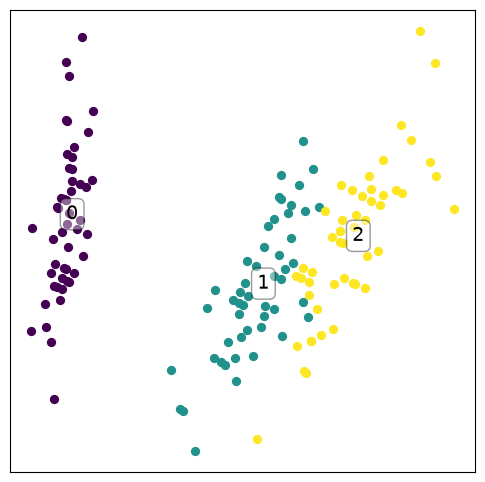

In [10]:
plotClusters(data2d, target, centroids=centroides)
plt.show()

Para clasificar una muestra desconocida basta con encontrar el centroide de clase más cercano y predecir esa clase. Resulta que este enfoque da lugar a **fronteras de clase lineales**: la frontera entre dos clases es el conjunto de puntos equidistantes a sus dos centroides, que en el plano es una recta. Esa propiedad, que verificaremos gráficamente en un momento, es la fortaleza y la limitación del método.

### 4.1 Implementación

Tres detalles de esta implementación que vale la pena señalar:

- `self.clases_` guarda las **etiquetas reales**. Es tentador devolver directamente el índice del
  centroide más cercano, pero eso solo coincide con la clase cuando las etiquetas son
  $0,1,2,\dots$ Con clases nombradas (`'setosa'`) o numeradas de otro modo, el resultado sería
  incorrecto.
- Se usa `argmin`, no `argsort`: solo necesitamos el mínimo, no el orden completo.
- El parámetro `metric` se pasa a `pairwise_distances`, así que puedes cambiar la distancia sin
  tocar el resto. Es la misma libertad que tenías con `distance_function` en el notebook 03.


In [19]:
np.argmax(pairwise_distances([[0,0], [1,1]], [[1,1],[0,0]],
                   metric='cityblock'), axis=1)

array([0, 1])

In [21]:
class NC:
    """Clasificador del centroide mas cercano."""

    def __init__(self, metric='euclidean'):
        self.metric = metric

    def fit(self, X, y):
        # Entrenar = promediar los elementos de cada clase
        self.clases_ = np.unique(y)
        self.centroides_ = {c: X[y == c].mean(axis=0) for c in self.clases_}
        self.C = np.array([self.centroides_[c] for c in self.clases_])
        return self

    def predict(self, X):
        d = pairwise_distances(X, self.C, metric=self.metric)
        # argmin da el INDICE del centroide; clases_ lo traduce a la etiqueta real
        return self.clases_[np.argmin(d, axis=1)]

In [27]:
clf = NC().fit(X_train, y_train)
print('centroides aprendidos:')
print(np.round(clf.C, 3))
print()
exactitud_nc = (clf.predict(X_test) == y_test).mean()
print('exactitud en PRUEBA: %.3f' % exactitud_nc)

centroides aprendidos:
[[-2.642  0.208]
 [ 0.52  -0.283]
 [ 2.213  0.113]]

exactitud en PRUEBA: 0.844


### 4.2 La frontera de decisión

Una forma de entender un clasificador es preguntarle **por cada punto del plano** qué clase
predice, y colorear el resultado. Eso hace `dibuja_frontera_2D`: construye una rejilla de
200×200 puntos, la clasifica completa y dibuja las regiones.


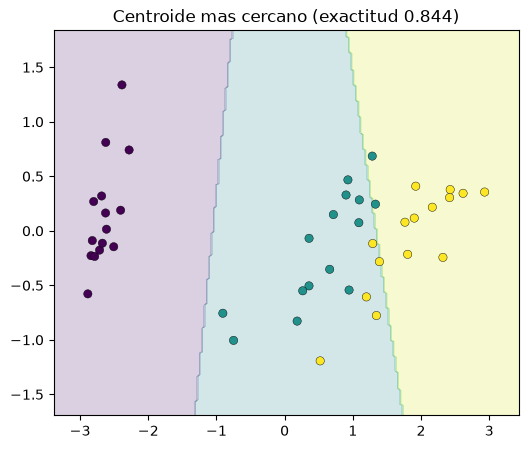

In [29]:
fig, ax = plt.subplots(figsize=(6, 5))
dibuja_frontera_2D(clf, X_test, y_test, ax=ax,
                   titulo='Centroide mas cercano (exactitud %.3f)' % exactitud_nc)
plt.show()

Confirmado: las fronteras son **rectas**. Y ahí se ve el origen de los errores, todos
concentrados en la zona donde versicolor y virginica se traslapan. Ninguna recta puede separar
bien esas dos nubes, así que ese error no se arregla con más datos: es una limitación del modelo.


## 5. k vecinos más cercanos (k-NN)


K-Nearest Neighbors (KNN) es un algoritmo supervisado de clasificación y regresión. Su principio básico es que, dado un objeto de clase desconocida, se determinan los $k$ objetos más cercanos del conjunto de entrenamiento y se le asigna la clase **mayoritaria** entre esos vecinos; en el caso de la regresión, el promedio de sus salidas.

### Pasos generales del KNN:

1. **Seleccionar el número de vecinos** \( k \) (es un hiper-parámetro).
2. **Calcular la distancia** entre $x_q$ y todos los puntos en el conjunto de datos de entrenamiento. La distancia euclidiana es una de las métricas más comunes y se calcula como:

$$d(x_q,x_i)=\sqrt{\Sigma_{j=1}^D (x_{q_j}-x_{i_j})^2}$$
   
   
   donde:
   - $x_q$ es el objeto de clase/salida desconocida.
   - $x_i$ es uno de los elementos del conjunto de entrenamiento $X$.
   - $D$ es el número de características o dimensiones.
   - $d$ La función de distancia


3. **Ordenar las distancias** y seleccionar los $k$ vecinos más cercanos.
4. **Clasificación**: En el caso de clasificación, se asigna  la categoría más frecuente entre sus $k$ vecinos.
   
   En términos de una función de predicción, esto se puede expresar como:

   
   $$ \hat{y} = \text{moda}(y_i), \quad \forall i \in N_k(x)$$
   donde $ N_k(x)$ representa el conjunto de los $k$ vecinos más cercanos, y $y_i$ es la clase del í-esimo vecino.

5. **Regresión**: En este caso, el valor a predecir será la media de los valores de los $k$ vecinos más cercanos:

  
   $$ \hat{y} = \frac{1}{k} \sum_{i \in N_k(x)} y_i$$

### Selección del valor de $k$:
- Si $k$ es pequeño, el modelo puede ser sensible al ruido y sobreajustarse (revisaremos este concepto en las siguientes seciones).
- Si $k$ es muy grande, el modelo puede perder la capacidad de capturar detalles locales y generar predicciones menos precisas.

Este algoritmo es sencillo pero puede ser computacionalmente costoso, ya que requiere calcular la distancia a todos los puntos del conjunto de entrenamiento para cada nuevo punto a clasificar o predecir.


Compara los dos algoritmos. Toda la diferencia está en **contra qué se compara** el objeto nuevo:

| | NC | k-NN |
|---|---|---|
| Entrenar | promediar cada clase | **nada**: solo guardar los datos / crear indice |
| Predecir | comparar contra $K$ centroides | comparar contra los $n$ ejemplos / busqueda de los k mas cercanos |
| Costo de predecir | $O(KD)$ | $O(nD)$ |
| Memoria | $K$ vectores | **todo** el entrenamiento |
| Frontera | lineal | arbitraria |

k-NN es un método **perezoso**: pospone todo el trabajo hasta el momento de predecir. Esa es la
razón de que sus fronteras puedan tener cualquier forma, y también de que sea caro cuando $n$
crece. Es el mismo compromiso que vimos entre k-centers y K-Means en el notebook 03: quien no
resume los datos paga después.


### 5.1 Una alternativa: el radio $\epsilon$
Otra alternativa al parámetro $k$ es fijar un radio $\epsilon$ que define una vecindad alrededor del punto de interés. En este enfoque, en vez de seleccionar un número específico de vecinos más cercanos, se consideran todos los puntos que caen dentro del radio $\epsilon$ del punto de datos nuevo.

En este caso el conjunto $N_k$ se define como
   
   $$N_\epsilon(x) = \left\{ x_i \mid d(x_q, x_i) \leq \epsilon \right\}$$
  

#### Ventajas de usar $\epsilon$:

- **Flexibilidad**: No es necesario especificar un número exacto de vecinos, lo cual puede ser útil en áreas de baja densidad, ya que el número de vecinos cercanos puede variar.
- **Adaptabilidad**: En áreas donde los puntos de datos están más dispersos, $ \epsilon$ puede permitir una selección de vecinos más adaptada al espacio de características.

#### Consideraciones al usar $\epsilon$:

- Si $\epsilon$ es muy pequeño, es posible que no se encuentren suficientes vecinos para hacer una predicción confiable.
- Si $\epsilon$ es demasiado grande, se pueden incluir demasiados puntos lejanos, lo que reduce la precisión del modelo al incorporar puntos menos relevantes.

Esta variante **la vas a implementar tú**, una vez que tengamos el protocolo de
evaluación de las secciones 6 a 8. Por ahora quédate con la idea: $k$ fija *cuántos* vecinos votan,
$\epsilon$ fija *hasta dónde* se buscan.


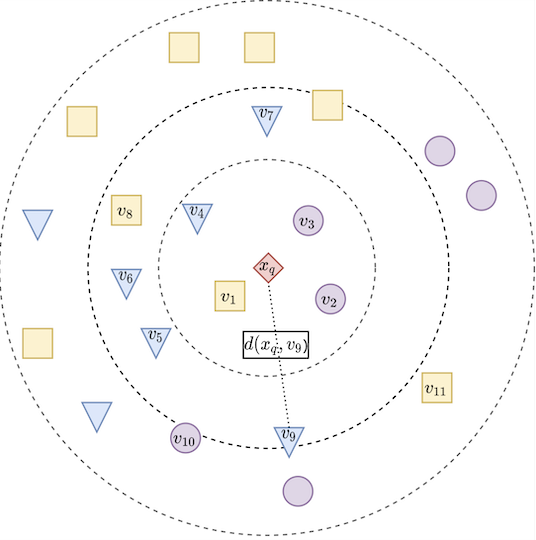

### 5.2 Implementación


In [30]:
class KNN:
    """Clasificador por votacion de los k vecinos mas cercanos."""

    def __init__(self, n_neighbors=3, metric='euclidean'):
        self.n_neighbors = n_neighbors
        self.metric = metric

    def fit(self, X, y):
        # Entrenar = memorizar. No hay parametros que ajustar.
        self.data = np.asarray(X)
        self.target = np.asarray(y)
        return self

    def predict(self, X):
        d = pairwise_distances(X, self.data, metric=self.metric)
        idx = np.argsort(d, axis=1)[:, :self.n_neighbors]   # los k mas cercanos
        return mode(self.target[idx], axis=1, keepdims=False).mode  # la clase mayoritaria

In [31]:
clfv = KNN(n_neighbors=11).fit(X_train, y_train)
exactitud_knn = (clfv.predict(X_test) == y_test).mean()

print('exactitud en PRUEBA')
print('  NC          : %.3f' % exactitud_nc)
print('  k-NN (k=11) : %.3f' % exactitud_knn)

exactitud en PRUEBA
  NC          : 0.844
  k-NN (k=11) : 0.956


Ahora sí la comparación es válida: **los dos números salen del mismo conjunto de prueba**, con
la misma partición. k-NN gana, y la siguiente figura muestra por qué.


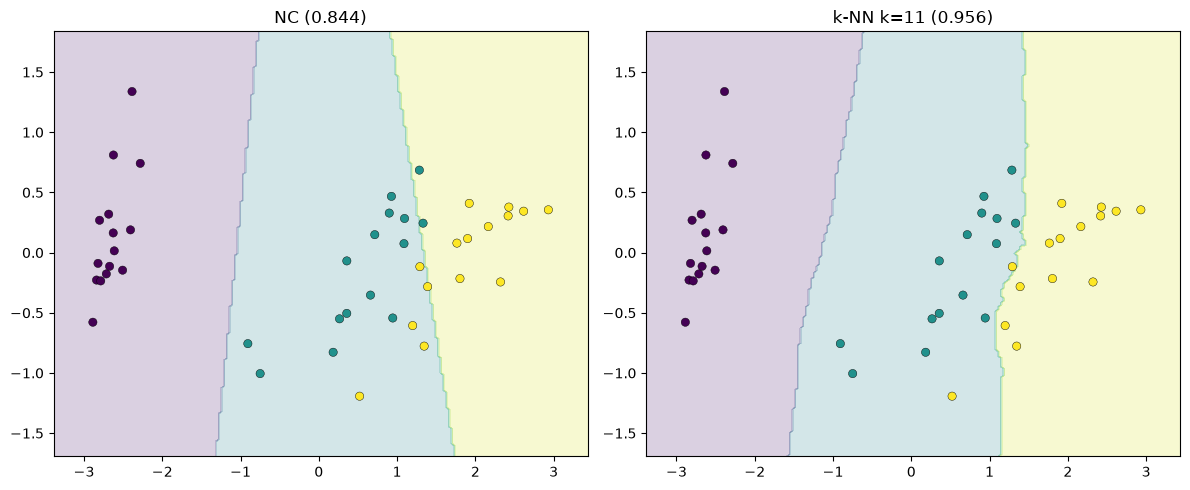

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
dibuja_frontera_2D(clf,  X_test, y_test, ax=axes[0],
                   titulo='NC (%.3f)' % exactitud_nc)
dibuja_frontera_2D(clfv, X_test, y_test, ax=axes[1],
                   titulo='k-NN k=11 (%.3f)' % exactitud_knn)
plt.tight_layout(); plt.show()

La frontera de k-NN **se curva** para seguir la forma de los datos en la zona de traslape.
Ninguna recta podía hacer eso.

> **Ejercicio 5.1** Vuelve a dibujar las dos fronteras con `k=1` y con `k=51`. ¿Cuál de las dos se
> parece más a la de NC, y por qué? Guarda tu respuesta: la sección 7 la explica con una gráfica.


## 6. La trampa: nunca midas en el entrenamiento

Aquí está el error más común al empezar, y conviene cometerlo a propósito una vez. Entrenemos k-NN con $k=1$ y midamos su exactitud **sobre los mismos datos de entrenamiento**.


In [33]:
k1 = KNN(n_neighbors=1).fit(X_train, y_train)
print('k-NN con k=1')
print('  exactitud en ENTRENAMIENTO: %.3f' % (k1.predict(X_train) == y_train).mean())
print('  exactitud en PRUEBA       : %.3f' % (k1.predict(X_test)  == y_test).mean())

k-NN con k=1
  exactitud en ENTRENAMIENTO: 1.000
  exactitud en PRUEBA       : 0.978


**100% en entrenamiento**, y no es que el modelo sea perfecto: el vecino más cercano de un punto
del entrenamiento **es él mismo**, a distancia cero. Con $k=1$, k-NN memoriza el conjunto.

Para ver que ese 1.000 no dice nada sobre la calidad del modelo, barajemos las etiquetas
destruyendo cualquier relación con los datos y midamos otra vez.


In [17]:
y_absurdo = np.random.permutation(y_train)   # etiquetas sin ninguna relacion con X
absurdo = KNN(n_neighbors=1).fit(X_train, y_absurdo)
print('etiquetas barajadas, k=1')
print('  exactitud en ENTRENAMIENTO: %.3f  <- no significa nada'
      % (absurdo.predict(X_train) == y_absurdo).mean())
print('  exactitud en PRUEBA       : %.3f  <- azar, como debe ser'
      % (absurdo.predict(X_test) == y_test).mean())

etiquetas barajadas, k=1
  exactitud en ENTRENAMIENTO: 0.990  <- no significa nada
  exactitud en PRUEBA       : 0.289  <- azar, como debe ser


La exactitud en entrenamiento se mantiene casi perfecta con etiquetas **completamente
aleatorias**, mientras que en prueba cae a la zona del azar. Es la
demostración de que ese número no mide nada útil.

> **¿Por qué 0.990 y no 1.000?** Iris contiene un par de flores con exactamente las mismas cuatro
> medidas (las filas 101 y 142). Al barajar les tocaron etiquetas distintas, y como ambas están a
> distancia cero de la otra, una de las dos necesariamente falla. Con las etiquetas reales no pasa,
> porque las dos son virginica.

Un modelo que memoriza y no generaliza está **sobreajustado** (*overfitting*). La exactitud en
entrenamiento no lo detecta; la de prueba sí. Por eso apartamos datos en la sección 3.

Con esto se entiende también la advertencia del inicio: si el notebook reportara NC medido en
prueba y k-NN medido en entrenamiento, la comparación estaría inclinada a favor de k-NN sin que
eso dijera nada sobre cuál generaliza mejor.


## 7. Elegir $k$: la curva de validación

$k$ es un **hiperparámetro**: no se aprende de los datos, la elige el usuario. Si
grafiquemos la exactitud en entrenamiento y en prueba para valores crecientes de $k$ obtnemos la siguiente grafica.


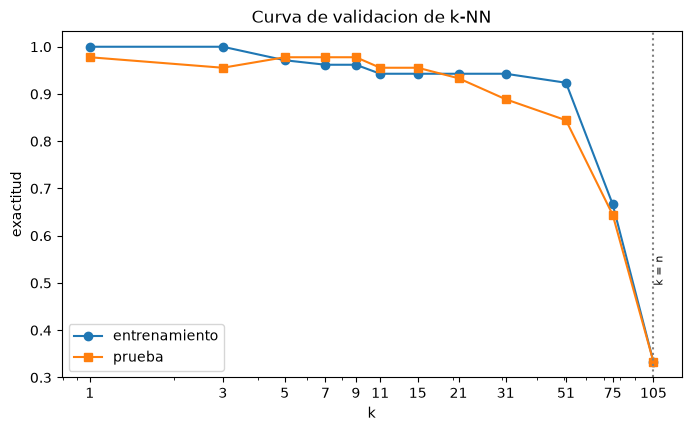

k,1,3,5,7,9,11,15,21,31,51,75,105
entrenamiento,1.000000,1.000000,0.971429,0.961905,0.961905,0.942857,0.942857,0.942857,0.942857,0.923810,0.666667,0.333333
prueba,0.977778,0.955556,0.977778,0.977778,0.977778,0.955556,0.955556,0.933333,0.888889,0.844444,0.644444,0.333333


In [34]:
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 105]
ac_train, ac_test = [], []
for k in ks:
    m = KNN(n_neighbors=k).fit(X_train, y_train)
    ac_train.append((m.predict(X_train) == y_train).mean())
    ac_test.append((m.predict(X_test) == y_test).mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, ac_train, marker='o', label='entrenamiento')
ax.plot(ks, ac_test,  marker='s', label='prueba')
ax.set_xlabel('k'); ax.set_ylabel('exactitud'); ax.set_xscale('log')
ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.axvline(len(X_train), color='gray', linestyle='dotted')
ax.annotate('k = n', (len(X_train), 0.5), rotation=90, fontsize=8)
ax.legend(); ax.set_title('Curva de validacion de k-NN')
plt.show()

pd.DataFrame({'k': ks, 'entrenamiento': ac_train, 'prueba': ac_test}).set_index('k').T

La curva tiene la forma característica de todo problema de selección de modelo:

- **$k$ pequeño** (izquierda): exactitud perfecta en entrenamiento, peor en prueba. El modelo es
  muy flexible y se ajusta al ruido. Es **sobreajuste**.
- **$k$ grande** (derecha): las dos curvas caen juntas. Al votar entre demasiados vecinos, se
  incluyen puntos de otras clases y el modelo pierde capacidad de distinguir. Es **subajuste**.
- **En el extremo $k=n$** (105, todo el entrenamiento), cada predicción vota con la colección
  completa y da lo mismo para todos los puntos: la exactitud se desploma a ~0.33, que es lo que da
  predecir siempre la misma clase entre tres.

$k$ controla la **complejidad** del modelo, en dirección inversa: $k$ chico, modelo complejo;
$k$ grande, modelo simple. La zona adecuada está en medio.


## 8. Elegir $k$ sin hacer trampa: validación cruzada

La curva anterior tiene un problema serio, y es sutil: si eliges el $k$ que maximiza la curva de
**prueba**, entonces usaste el conjunto de prueba para tomar una decisión. Ya no es un conjunto
que el modelo "nunca vio", y la exactitud que reportes será optimista.

La salida estándar es la **validación cruzada de $m$ pliegues** ($m$-fold cross validation),
aplicada **solo al conjunto de entrenamiento**:

1. Se parte el entrenamiento en $m$ pliegues del mismo tamaño.
2. Para cada pliegue: se entrena con los otros $m-1$ y se evalúa en él.
3. La calidad del hiperparámetro es el promedio de los $m$ resultados.

Así cada ejemplo del entrenamiento sirve de validación exactamente una vez, y el conjunto de
prueba **sigue intacto**. `StratifiedKFold` además conserva la proporción de clases en cada
pliegue.


In [37]:
def cv_knn(X, y, k, m=5, semilla=0):
    """Exactitud promedio de k-NN por validacion cruzada de m pliegues."""
    skf = StratifiedKFold(n_splits=m, shuffle=True, random_state=semilla)
    puntajes = []
    for i_train, i_val in skf.split(X, y):
        modelo = KNN(n_neighbors=k).fit(X[i_train], y[i_train])
        puntajes.append((modelo.predict(X[i_val]) == y[i_val]).mean())
    return np.mean(puntajes), np.std(puntajes)

resultados = []
for k in ks[:-2]:                       # k debe ser menor que el tamaño de un pliegue
    media, desv = cv_knn(X_train, y_train, k)
    resultados.append((k, media, desv))

tabla = pd.DataFrame(resultados, columns=['k', 'cv_media', 'cv_desv']).set_index('k')
tabla

,cv_media,cv_desv
k,,
1,0.961905,0.035635
3,0.961905,0.019048
5,0.961905,0.019048
7,0.961905,0.019048
9,0.942857,0.019048
11,0.942857,0.019048
15,0.933333,0.023328
21,0.942857,0.019048
31,0.923810,0.023328


In [21]:
mejor = tabla.cv_media.max()
# Entre los k empatados elegimos el MAYOR: a igualdad de resultados, el modelo mas simple
candidatos = tabla.index[np.isclose(tabla.cv_media, mejor)]
k_elegido = int(candidatos.max())
print('mejor puntaje de CV : %.3f' % mejor)
print('k empatados         : %s' % list(candidatos))
print('k elegido           : %d' % k_elegido)

mejor puntaje de CV : 0.962
k empatados         : [1, 3, 5, 7]
k elegido           : 7


Que varios valores de $k$ empaten es normal, y el criterio para desempatar no es arbitrario:
**a igualdad de desempeño, se prefiere el modelo más simple**, que aquí es el $k$ más grande.
Un $k$ mayor promedia sobre más vecinos y es menos sensible al ruido, así que es más probable que
el empate se sostenga en datos nuevos.

Ahora, y solo ahora, tocamos el conjunto de prueba.


In [22]:
final = KNN(n_neighbors=k_elegido).fit(X_train, y_train)
print('=== Resultado final, medido UNA sola vez ===')
print('k elegido por validacion cruzada: %d' % k_elegido)
print('exactitud en prueba             : %.3f' % (final.predict(X_test) == y_test).mean())
print()
print('Referencia: NC en el mismo conjunto de prueba: %.3f' % exactitud_nc)

=== Resultado final, medido UNA sola vez ===
k elegido por validacion cruzada: 7
exactitud en prueba             : 0.978

Referencia: NC en el mismo conjunto de prueba: 0.844


> **Ejercicio 8.1** Repite la validación cruzada con `semilla=1, 2, 3`. ¿Cambia el $k$ elegido?
> Fíjate en la columna `cv_desv`: si la desviación entre pliegues es comparable a la diferencia
> entre dos valores de $k$, esa diferencia no es concluyente.
>
> **Ejercicio 8.2** Usa `cv_knn` para elegir también la **métrica** (`'euclidean'`, `'manhattan'`,
> `'cosine'`), no solo $k$. Tendrás que modificar la función para que reciba el parámetro.


## 9. Cuándo NC no funciona

La sección 4 afirmó que NC produce fronteras **lineales**. Esa no es una limitación menor:
significa que hay problemas donde NC no puede acertar por más datos que le des.

El caso extremo son datos concéntricos: dos clases donde una rodea a la otra. Los centroides de
ambas clases caen prácticamente en el mismo punto.


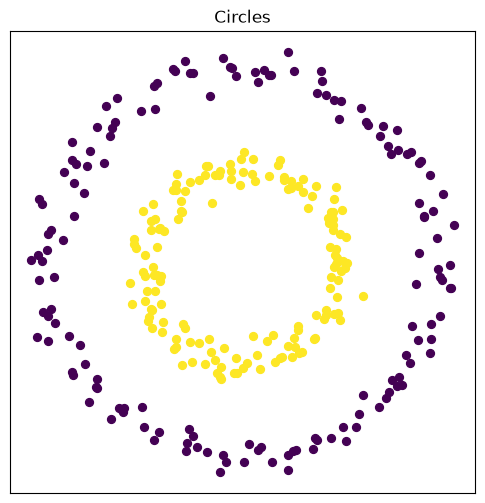

In [39]:
Xc, yc = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=0)
plotClusters(Xc, yc)
plt.title("Circles");


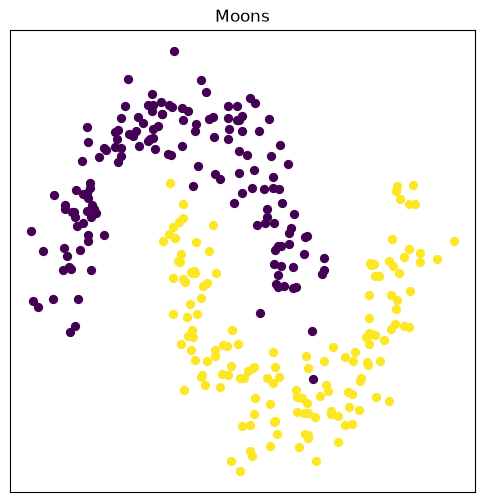

In [40]:
Xm, ym = make_moons(n_samples=300, noise=0.15, random_state=0)
plotClusters(Xm, ym)
plt.title("Moons");

En `circles` los dos centroides están casi encima uno del otro. Un clasificador que solo mira
"a qué centroide estoy más cerca" no tiene información con que decidir.


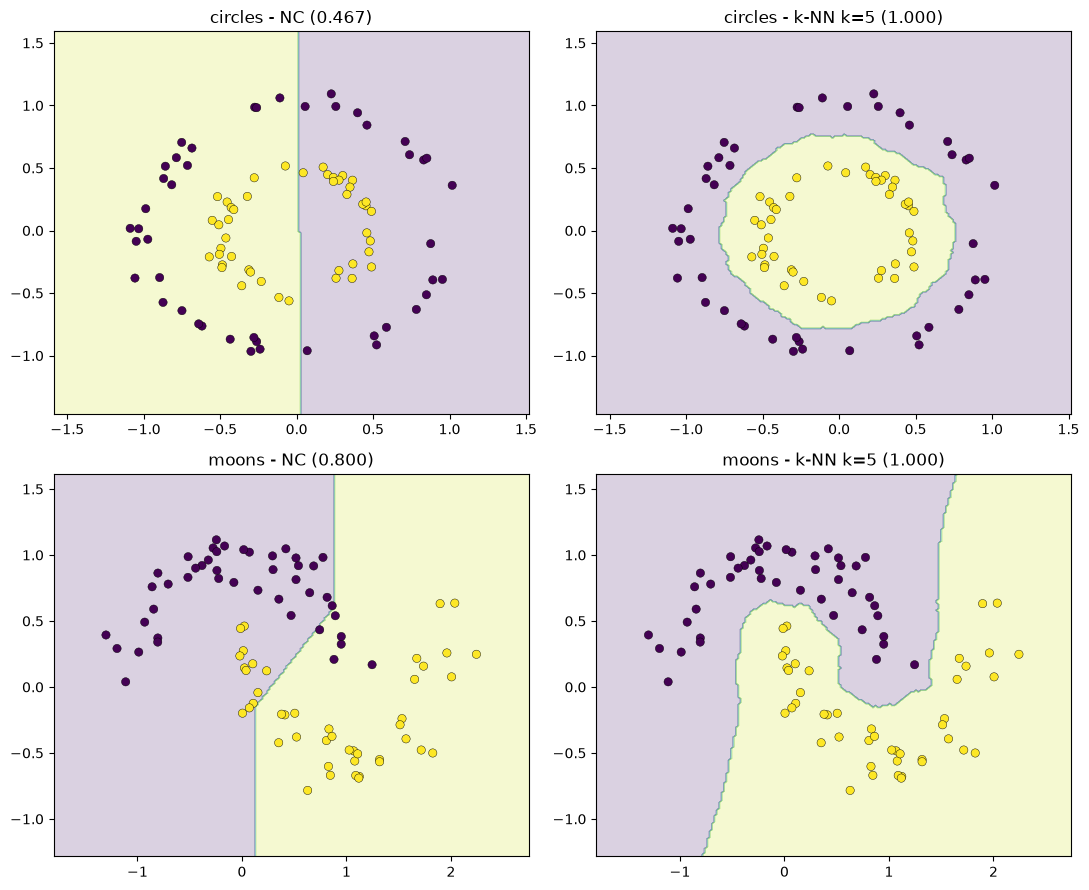

modelo,NC,k-NN k=5
datos,,
circles,0.466667,1.0
moons,0.800000,1.0


In [57]:
filas = []
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for fila, (Xn, yn, nombre) in enumerate([(Xc, yc, 'circles'), (Xm, ym, 'moons')]):
    Xa, Xb, ya, yb = train_test_split(Xn, yn, test_size=0.3, random_state=1, stratify=yn)
    for col, (Modelo, etiqueta) in enumerate([(lambda: NC(metric='manhattan'), 'NC'),
                                              (lambda: KNN(n_neighbors=5), 'k-NN k=5')]):
        m = Modelo().fit(Xa, ya)
        a = (m.predict(Xb) == yb).mean()
        filas.append((nombre, etiqueta, a))
        dibuja_frontera_2D(m, Xb, yb, ax=axes[fila][col],
                           titulo='%s - %s (%.3f)' % (nombre, etiqueta, a))
plt.tight_layout(); plt.show()

pd.DataFrame(filas, columns=['datos', 'modelo', 'exactitud']).pivot(
    index='datos', columns='modelo', values='exactitud')

En `circles`, NC baja de 0.5: **peor que lanzar una moneda**. No es mala suerte, es geometría.
Con los centroides superpuestos, la recta que los separa queda en una posición arbitraria y parte
los anillos por la mitad. k-NN acierta el 100%, porque para decidir solo necesita mirar quiénes
son sus vecinos inmediatos, y los vecinos de un punto del anillo exterior son del anillo exterior.

En `moons` pasa lo mismo, menos dramático: 0.79 contra 1.00.


> **Ejercicio 9.1** Sube el ruido de `make_moons` a `noise=0.4` y repite. ¿Sigue ganando k-NN por
> tanto? ¿Qué le pasa a la frontera de k-NN cuando las clases se traslapan de verdad?


## 10. Recuerda la escala

k-NN y NC son distancias más un `argmin`, así que arrastran el problema del notebook 02, sección 7.
Volvemos a iris, ahora **en sus cuatro dimensiones originales**, y repetimos el experimento de las
unidades: sépalo en milímetros, pétalo en centímetros.


In [44]:
def exactitud_knn(X, k=5, semilla=1):
    Xa, Xb, ya, yb = train_test_split(X, target, test_size=0.3,
                                      random_state=semilla, stratify=target)
    return (KNN(n_neighbors=k).fit(Xa, ya).predict(Xb) == yb).mean()

data_mm = data.copy()
data_mm[:, 0] *= 10   # sepal length: cm -> mm
data_mm[:, 1] *= 10   # sepal width : cm -> mm

# Promediamos sobre 20 particiones para que no dependa del sorteo
conjuntos = [('iris en cm', data),
             ('sepalo en mm', data_mm),
             ('sepalo en mm + StandardScaler', StandardScaler().fit_transform(data_mm))]
for nombre, X in conjuntos:
    v = [exactitud_knn(X, 5, s) for s in range(20)]
    print('%-32s media %.3f   peor caso %.3f' % (nombre, np.mean(v), np.min(v)))

iris en cm                       media 0.967   peor caso 0.911
sepalo en mm                     media 0.797   peor caso 0.689
sepalo en mm + StandardScaler    media 0.951   peor caso 0.889


La exactitud cae de 0.967 a 0.797 solo por cambiar las unidades de dos columnas, y el escalado
la recupera a 0.951. Es el mismo fenómeno que en el notebook 02: la característica de rango mayor
domina la distancia, los vecinos cambian, y las predicciones con ellos.

**Un detalle que sí es específico de clasificación**: el escalador se ajusta con el
**entrenamiento** y luego se aplica al de prueba. Si calculas la media y la desviación usando
todos los datos, estás filtrando información del conjunto de prueba hacia el modelo
(*data leakage*). La forma correcta:

```python
escalador = StandardScaler().fit(X_train)   # ajustar solo con entrenamiento
X_train_s = escalador.transform(X_train)
X_test_s  = escalador.transform(X_test)     # aplicar, no reajustar
```


### 10.1 El costo de proyectar a 2D

Todo el notebook trabajó en el espacio de PCA para poder dibujar. Midamos el precio.


In [51]:
for nombre, X in [('PCA 2 dimensiones', data2d), ('original 4 dimensiones', data)]:
    Xa, Xb, ya, yb = train_test_split(X, target, test_size=0.3, random_state=1, stratify=target)
    nc = NC().fit(Xa, ya)
    kn = KNN(n_neighbors=3).fit(Xa, ya)
    print('%-24s  NC %.3f   k-NN %.3f'
          % (nombre, (nc.predict(Xb) == yb).mean(), (kn.predict(Xb) == yb).mean()))

PCA 2 dimensiones         NC 0.844   k-NN 0.956
original 4 dimensiones    NC 0.889   k-NN 0.978


Los dos modelos mejoran en el espacio completo. Las figuras de este notebook son didácticas;
los números que reportes en tu trabajo deben salir del espacio original.


## 11. Ejercicio de implementación: `RadiusNN`

La sección 5.1 describió la variante del radio $\epsilon$; aquí la
implementas y la evalúas con el protocolo de las secciones 6 a 8.

La diferencia de fondo con k-NN es que **el número de vecinos ya no es fijo**: depende de cuántos
caigan dentro del radio. Eso trae una complicación que k-NN no tiene y que es el corazón del
ejercicio: **la vecindad puede quedar vacía**. Si ningún punto de entrenamiento está a distancia
$\le \epsilon$, no hay con qué votar, y el algoritmo tiene que decidir algo. Las opciones
razonables son:

- predecir la clase mayoritaria del entrenamiento,
- predecir el vecino más cercano aunque esté fuera del radio (es decir, caer a $k=1$),
- devolver una etiqueta especial de "no sé", que en la literatura se trata como detección de
  atípicos.

Ninguna es "la correcta": **elige una, impleméntala y justifícala**. Eso es parte del ejercicio.


In [53]:
class RadiusNN:
    """Clasificador que vota entre los vecinos dentro de un radio epsilon.

    A diferencia de KNN, el numero de vecinos NO es fijo: depende de cuantos
    puntos de entrenamiento caigan dentro del radio.
    """

    def __init__(self, epsilon=1.0, metric='euclidean'):
        self.epsilon = epsilon
        self.metric = metric

    def fit(self, X, y):
        raise NotImplementedError('te toca escribir fit')

    def predict(self, X):
        raise NotImplementedError('te toca escribir predict')

### 11.1 Pruebas

Como en el notebook 03, aquí tienes con qué verificarte. Mientras `fit` o `predict` sigan sin
implementar, las pruebas se reportan como pendientes en lugar de reventar.


In [54]:
def verificar_radius(epsilon=0.5, Xtr=None, ytr=None, Xte=None, yte=None):
    """Bateria de pruebas para RadiusNN."""
    Xtr = X_train if Xtr is None else Xtr
    ytr = y_train if ytr is None else ytr
    Xte = X_test  if Xte is None else Xte
    yte = y_test  if yte is None else yte

    print('=== RadiusNN, epsilon=%.3g ===' % epsilon)
    try:
        modelo = RadiusNN(epsilon=epsilon).fit(Xtr, ytr)
        yp = np.asarray(modelo.predict(Xte))
    except NotImplementedError as e:
        print('[PEND. ] %s' % e)
        return []

    resultados = []
    def prueba(nombre, fn):
        try:
            ok, detalle = fn()
        except Exception as e:
            resultados.append((nombre, False, '%s: %s' % (type(e).__name__, e)))
        else:
            resultados.append((nombre, bool(ok), detalle))  # bool(): numpy.bool_ rompe 'is True'

    mayoritaria = np.bincount(ytr).argmax()
    linea_base = (yte == mayoritaria).mean()
    diametro = pairwise_distances(Xtr).max()

    prueba('una etiqueta por elemento',
           lambda: (len(yp) == len(yte), 'obtuvo %d de %d' % (len(yp), len(yte))))

    prueba('las etiquetas son clases vistas en entrenamiento',
           lambda: (set(np.unique(yp)) <= set(np.unique(ytr)),
                    'predichas: %s' % np.unique(yp)))

    def _vacias():
        # epsilon diminuto: TODAS las vecindades quedan vacias
        m = RadiusNN(epsilon=1e-12).fit(Xtr, ytr)
        salida = np.asarray(m.predict(Xte))
        return (len(salida) == len(yte), 'no lanzo excepcion y devolvio %d etiquetas' % len(salida))
    prueba('sobrevive a vecindades vacias (epsilon -> 0)', _vacias)

    def _todo_dentro():
        # epsilon mayor que el diametro: todos votan, gana la clase mayoritaria
        m = RadiusNN(epsilon=diametro * 2).fit(Xtr, ytr)
        salida = np.asarray(m.predict(Xte))
        return ((salida == mayoritaria).all(),
                'con epsilon=%.2f predice siempre %s' % (diametro * 2, np.unique(salida)))
    prueba('epsilon enorme -> siempre la clase mayoritaria', _todo_dentro)

    def _identidad():
        # con un radio minimo, el unico vecino de un punto de entrenamiento es el mismo
        m = RadiusNN(epsilon=1e-6).fit(Xtr, ytr)
        salida = np.asarray(m.predict(Xtr[:30]))
        return ((salida == ytr[:30]).all(), 'los 30 primeros se clasifican en su propia clase')
    prueba('un punto de entrenamiento se predice a si mismo', _identidad)

    exactitud = (yp == yte).mean()
    prueba('supera a predecir siempre la clase mayoritaria',
           lambda: (exactitud > linea_base,
                    'exactitud %.3f vs linea base %.3f' % (exactitud, linea_base)))

    ancho = max(len(n) for n, _, _ in resultados)
    for nombre, ok, detalle in resultados:
        marca = {True: '  OK  ', False: 'FALLA '}[ok]
        print('[%s] %-*s  %s' % (marca, ancho, nombre, detalle))
    pasan = sum(1 for _, ok, _ in resultados if ok is True)
    print('--- %d de %d pruebas pasan' % (pasan, len(resultados)))
    return resultados


_ = verificar_radius(epsilon=0.5)

=== RadiusNN, epsilon=0.5 ===
[PEND. ] te toca escribir fit


### 11.2 Cuando pase las pruebas

Estas dos celdas son el análisis que se te pide. La primera dibuja la frontera para varios radios;
la segunda es la curva de validación de $\epsilon$, análoga a la de $k$ de la sección 7.


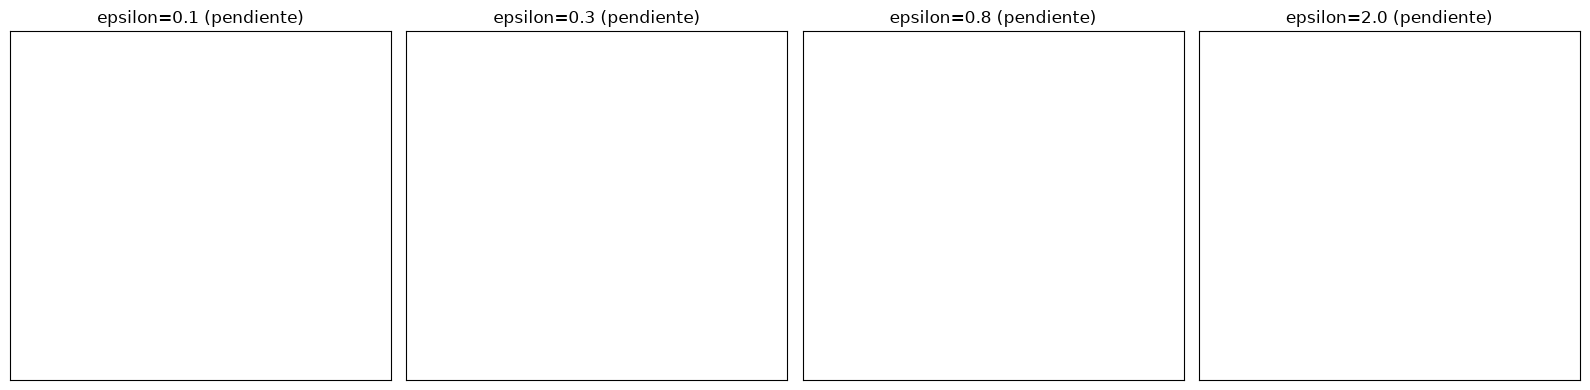

In [55]:
epsilons = [0.1, 0.3, 0.8, 2.0]
fig, axes = plt.subplots(1, len(epsilons), figsize=(4 * len(epsilons), 4))
for ax, eps in zip(np.atleast_1d(axes), epsilons):
    try:
        m = RadiusNN(epsilon=eps).fit(X_train, y_train)
        a = (np.asarray(m.predict(X_test)) == y_test).mean()
        dibuja_frontera_2D(m, X_test, y_test, ax=ax,
                           titulo='epsilon=%.1f (%.3f)' % (eps, a))
    except NotImplementedError:
        ax.set_title('epsilon=%.1f (pendiente)' % eps)
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [56]:
try:
    filas = []
    for eps in [0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.2, 2.0, 4.0, 8.0]:
        m = RadiusNN(epsilon=eps).fit(X_train, y_train)
        d = pairwise_distances(X_test, X_train)
        vacias = int((d.min(axis=1) > eps).sum())   # cuantas vecindades quedan vacias
        filas.append((eps, (np.asarray(m.predict(X_test)) == y_test).mean(), vacias))
    tabla_eps = pd.DataFrame(filas, columns=['epsilon', 'exactitud', 'vecindades_vacias'])
    print(tabla_eps.to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(tabla_eps.epsilon, tabla_eps.exactitud, marker='o', label='exactitud')
    ax.set_xscale('log'); ax.set_xlabel('epsilon'); ax.set_ylabel('exactitud')
    ax2 = ax.twinx()
    ax2.plot(tabla_eps.epsilon, tabla_eps.vecindades_vacias, marker='s',
             color='gray', linestyle='dashed', label='vecindades vacias')
    ax2.set_ylabel('vecindades vacias')
    ax.set_title('Curva de validacion de epsilon')
    fig.legend(loc='lower right', bbox_to_anchor=(0.9, 0.15))
    plt.show()
except NotImplementedError:
    print('Pendiente: implementa RadiusNN para generar esta curva.')

Pendiente: implementa RadiusNN para generar esta curva.


### 11.3 Preguntas a responder

1. ¿Qué le pasa a la frontera cuando $\epsilon$ es muy pequeño? Identifica en la figura la región
   donde actúa tu decisión para la vecindad vacía: se reconoce porque es una zona de color uniforme
   que no sigue la forma de los datos.
2. ¿Y cuando $\epsilon$ es muy grande? Relaciónalo con lo que pasaba en la sección 7 al hacer
   $k \to n$.
3. Compara tu curva de $\epsilon$ con la curva de $k$ de la sección 7. ¿Cuál de los dos
   hiperparámetros te parece más fácil de elegir, y por qué? Piensa en qué unidades está cada uno.
4. Adapta la función `cv_knn` de la sección 8 para elegir $\epsilon$ por validación cruzada.
   Compara el resultado en prueba contra el k-NN de la sección 8.
5. `sklearn.neighbors.RadiusNeighborsClassifier` resuelve el mismo problema. Por omisión **lanza
   una excepción** cuando la vecindad queda vacía, y hay que pasarle `outlier_label` para evitarlo.
   Compara tu implementación con la de scikit-learn usando `outlier_label='most_frequent'`, y
   comenta esa decisión de diseño: ¿es mejor fallar ruidosamente o inventar una respuesta?


## 12. Resumen

| Concepto | Idea en una línea |
|---|---|
| Clasificación | hay etiquetas, y por lo tanto una respuesta correcta que se puede medir |
| Entrenamiento / prueba | el conjunto de prueba se toca una sola vez, al final |
| NC | promedia cada clase; fronteras rectas; barato |
| k-NN | memoriza todo y vota; fronteras curvas; caro al predecir |
| Sobreajuste | exactitud perfecta en entrenamiento que no se sostiene en prueba |
| $k$ | controla la complejidad, en dirección inversa |
| Validación cruzada | elegir hiperparámetros sin gastar el conjunto de prueba |
| Escalado | obligatorio en todo método basado en distancias |
| $\epsilon$ | fija hasta dónde buscar, en vez de cuántos vecinos |

## 13. Ejercicios

1. Implementa `NC` con `metric='manhattan'` y `metric='cosine'` y compara las tres fronteras sobre
   iris en 2D. ¿Siguen siendo rectas? Explica el resultado a partir de la definición de cada
   distancia (notebook 02).
2. Escribe una función `curva_de_validacion(X, y, ks)` que devuelva la figura de la sección 7 para
   cualquier conjunto de datos, y aplícala a `moons`. ¿El $k$ óptimo es el mismo que para iris?
   ¿Por qué esperarías que dependa del conjunto?
3. Compara tu `KNN` contra `sklearn.neighbors.KNeighborsClassifier` con el mismo $k$ y la misma
   partición. Deben coincidir. Si no coinciden, investiga cómo desempata scikit-learn los votos.
4. Con tu `RadiusNN` de la sección 11, cuenta en cuántos puntos de prueba la vecindad queda vacía
   para distintos `epsilon` y grafícalo contra la exactitud. ¿Cómo elegirías `epsilon`?
5. **Integrador.** Toma el conjunto de datos que usaste para la tarea del notebook 03 y compara
   dos cosas: las etiquetas que encontró tu K-Means (sin usar las clases) contra las predicciones
   de k-NN (usándolas). Evalúa el agrupamiento con ARI y el clasificador con exactitud. ¿Qué te
   dice la diferencia entre ambos números sobre tus datos?
